# Task 2 (Medium) — GNN on Music Segment Graphs (FMA-small)

**Course:** CSE425 / EEE474 / CSE715 — GNN-Based BERT for Understanding Context from Music
**This notebook:** Task 2 only — GraphSAGE encoder on chroma-based segment graphs, genre
classification on **FMA-small**, compared against a **CNN-on-mel-spectrogram** baseline.

Pipeline (matches the project spec):
1. Load FMA-small metadata → 8 top-level genre labels.
2. For each track: resample to 22,050 Hz → split into fixed-length segments → chroma features per segment.
3. Build a **segment graph** per track: nodes = segments, edges = temporal adjacency + cosine-similarity (chroma) above a threshold.
4. Cache graphs as `.pt` files (so you never have to re-run audio processing).
5. Train a **GraphSAGE** encoder + mean-pool readout → genre classifier.
6. Train a **CNN baseline** on mel-spectrograms (no graph, no text) for comparison.
7. Report Macro-F1 / Micro-F1 / Accuracy for both, plot curves, save results.

> Your hardware (RTX 3070 Ti 8GB, 32GB RAM, i7-12700K) is comfortable for FMA-small
> (~8,000 tracks, 30s clips, ~7.2GB total).


## 0. Setup

Run this once. `torch_geometric` install command depends on your installed torch + CUDA
version — check `torch.__version__` and `torch.version.cuda` first if the wheel install fails.


In [17]:
# ---- One-time installs (uncomment as needed) ----
# !pip install librosa soundfile pandas numpy scikit-learn matplotlib tqdm
# !pip install torch --index-url https://download.pytorch.org/whl/cu121   # match your CUDA
# !pip install torch_geometric
# For PyG optional deps (faster scatter/sparse ops) — find the right wheel for your torch+cuda at:
# https://pytorch-geometric.com/whl/
# !pip install pyg_lib torch_scatter torch_sparse -f https://data.pyg.org/whl/torch-2.3.0+cu121.html
print("If imports below fail, run the installs above in a fresh cell.")


If imports below fail, run the installs above in a fresh cell.


In [18]:
import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset as TorchDataset, DataLoader as TorchDataLoader

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import SAGEConv, global_mean_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


Device: cuda - NVIDIA GeForce RTX 3070 Ti


## 1. Config — EDIT THESE PATHS

`AUDIO_DIR` is your FMA-small audio root (the folder containing `000/`, `001/`, ... `154/`).
`METADATA_DIR` should point to the FMA metadata folder containing `tracks.csv` and `genres.csv`
(from the official FMA metadata release, or bundled in your Kaggle download under a
`fma_metadata` folder — check your download for it).


In [19]:
CONFIG = {
    "AUDIO_DIR": r"E:\CSE715\Datasets\fma_small_medium_modarate\fma_small\fma_small",
    "METADATA_DIR": r"E:\CSE715\Datasets\fma_small_medium_modarate\fma_metadata",
    "CACHE_DIR": r"E:\CSE715\Datasets\fma_small_cache_v2",   # NEW cache dir — avoids reusing stale v1 features
    "RESULTS_DIR": r"./results",

    # --- Audio / segmentation ---
    "SAMPLE_RATE": 22050,
    "SEGMENT_SECONDS": 3.0,      # shorter windows -> ~10 nodes/graph instead of ~6
    "N_CHROMA": 12,
    "N_MFCC": 13,                 # NEW: timbral features
    "SIM_THRESHOLD": 0.90,
    "MAX_TRACKS": None,
    "FEATURE_VERSION": "v2_chroma_mfcc_contrast",  # bump this any time you change feature extraction

    # --- Mel-spectrogram (for CNN baseline) ---
    "N_MELS": 128,
    "CLIP_SECONDS": 29.0,          # use (nearly) full 30s clip, not a 15s crop
    "MEL_FIXED_FRAMES": None,      # computed automatically below from CLIP_SECONDS

    # --- Training ---
    "BATCH_SIZE": 32,
    "HIDDEN_DIM": 128,
    "NUM_GNN_LAYERS": 3,
    "DROPOUT": 0.3,
    "LR": 1e-3,
    "WEIGHT_DECAY": 1e-5,
    "EPOCHS": 60,                   # a bit more headroom; early stopping will cut it short if needed
    "PATIENCE": 10,
}

# hop_length defaults to 512 in librosa
CONFIG["MEL_FIXED_FRAMES"] = int(np.ceil(CONFIG["CLIP_SECONDS"] * CONFIG["SAMPLE_RATE"] / 512))

os.makedirs(CONFIG["CACHE_DIR"], exist_ok=True)
os.makedirs(os.path.join(CONFIG["CACHE_DIR"], "graphs"), exist_ok=True)
os.makedirs(os.path.join(CONFIG["CACHE_DIR"], "melspec"), exist_ok=True)
os.makedirs(CONFIG["RESULTS_DIR"], exist_ok=True)
print("Config ready. MEL_FIXED_FRAMES =", CONFIG["MEL_FIXED_FRAMES"])

Config ready. MEL_FIXED_FRAMES = 1249


## 2. Load FMA-small metadata & genre labels

FMA's `tracks.csv` has a 3-row multi-index header. We filter to `subset == 'small'` and use
`('track', 'genre_top')` as the single top-level genre label (8 classes in FMA-small).


In [20]:
def load_fma_metadata(metadata_dir, audio_dir, max_tracks=None):
    tracks_path = os.path.join(metadata_dir, "tracks.csv")
    tracks = pd.read_csv(tracks_path, index_col=0, header=[0, 1])

    small = tracks[tracks[('set', 'subset')] == 'small'].copy()
    small = small[small[('track', 'genre_top')].notna()]

    df = pd.DataFrame({
        "track_id": small.index.astype(int),
        "genre_top": small[('track', 'genre_top')].astype(str),
        "split": small[('set', 'split')].astype(str),   # official 'training'/'validation'/'test'
    })

    # try to grab artist id for leakage-aware sanity checks (not strictly required for the split
    # since we use FMA's official split column, which already avoids artist leakage)
    try:
        df["artist_id"] = small[('artist', 'id')].values
    except KeyError:
        df["artist_id"] = -1

    # keep only tracks whose mp3 actually exists on disk
    def audio_path(tid):
        s = f"{tid:06d}"
        return os.path.join(audio_dir, s[:3], s + ".mp3")

    df["path"] = df["track_id"].apply(audio_path)
    df = df[df["path"].apply(os.path.isfile)].reset_index(drop=True)

    if max_tracks is not None:
        df = df.sample(n=min(max_tracks, len(df)), random_state=SEED).reset_index(drop=True)

    return df

meta_df = load_fma_metadata(CONFIG["METADATA_DIR"], CONFIG["AUDIO_DIR"], CONFIG["MAX_TRACKS"])
print(f"Loaded {len(meta_df)} tracks with existing audio files.")
print(meta_df["genre_top"].value_counts())

le = LabelEncoder()
meta_df["label"] = le.fit_transform(meta_df["genre_top"])
NUM_CLASSES = len(le.classes_)
print("Classes:", list(le.classes_))
meta_df.head()


Loaded 8000 tracks with existing audio files.
genre_top
Hip-Hop          1000
Pop              1000
Folk             1000
Experimental     1000
Rock             1000
International    1000
Electronic       1000
Instrumental     1000
Name: count, dtype: int64
Classes: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']


,track_id,genre_top,split,artist_id,path,label
0,2,Hip-Hop,training,1,E:\CSE715\Datasets\fma_small_medium_modarate\f...,3
1,5,Hip-Hop,training,1,E:\CSE715\Datasets\fma_small_medium_modarate\f...,3
2,10,Pop,training,6,E:\CSE715\Datasets\fma_small_medium_modarate\f...,6
3,140,Folk,training,54,E:\CSE715\Datasets\fma_small_medium_modarate\f...,2
4,141,Folk,training,54,E:\CSE715\Datasets\fma_small_medium_modarate\f...,2


## 3. Audio → segment chroma features & graph construction

For each track:
1. Load audio at 22,050 Hz.
2. Split into fixed `SEGMENT_SECONDS` windows.
3. For each segment, compute mean+std chroma (24-dim node feature) — chroma is well-suited
   as an initial "chord-aware" audio feature per the spec.
4. Build edges: **temporal adjacency** (i, i+1) + **similarity edges** where cosine similarity
   of chroma means exceeds `SIM_THRESHOLD`.


In [21]:
def build_segment_graph(path, sr, seg_seconds, n_chroma, n_mfcc, sim_threshold):
    y, _ = librosa.load(path, sr=sr, mono=True)
    seg_len = int(seg_seconds * sr)
    n_segments = max(1, len(y) // seg_len)
    if n_segments < 2:
        return None

    node_feats = []
    for i in range(n_segments):
        seg = y[i * seg_len:(i + 1) * seg_len]
        if len(seg) < sr * 0.5:  # skip near-empty tail segment
            continue

        chroma = librosa.feature.chroma_stft(y=seg, sr=sr, n_chroma=n_chroma)
        mfcc = librosa.feature.mfcc(y=seg, sr=sr, n_mfcc=n_mfcc)
        contrast = librosa.feature.spectral_contrast(y=seg, sr=sr)
        centroid = librosa.feature.spectral_centroid(y=seg, sr=sr)
        zcr = librosa.feature.zero_crossing_rate(seg)
        rms = librosa.feature.rms(y=seg)

        feat = np.concatenate([
            chroma.mean(axis=1), chroma.std(axis=1),        # 24  - harmony
            mfcc.mean(axis=1), mfcc.std(axis=1),              # 26  - timbre
            contrast.mean(axis=1), contrast.std(axis=1),       # 14  - timbre/texture
            centroid.mean(axis=1), centroid.std(axis=1),        # 2   - brightness
            zcr.mean(axis=1), zcr.std(axis=1),                    # 2   - percussiveness
            rms.mean(axis=1), rms.std(axis=1),                     # 2   - dynamics
        ])  # total 70-dim, vs. the old 24-dim chroma-only
        node_feats.append(feat)

    if len(node_feats) < 2:
        return None
    x = np.stack(node_feats).astype(np.float32)

    norm = x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-8)
    sim = norm @ norm.T
    n_segments = x.shape[0]

    edges = set()
    for i in range(n_segments - 1):
        edges.add((i, i + 1)); edges.add((i + 1, i))
    for i in range(n_segments):
        for j in range(i + 1, n_segments):
            if sim[i, j] > sim_threshold:
                edges.add((i, j)); edges.add((j, i))
    if not edges:
        for i in range(n_segments - 1):
            edges.add((i, i + 1)); edges.add((i + 1, i))

    edge_index = np.array(list(edges)).T
    edge_attr = np.array([sim[i, j] for i, j in edges], dtype=np.float32).reshape(-1, 1)
    return x, edge_index, edge_attr


def track_graph_cache_path(cache_dir, track_id, feature_version):
    # NOTE: cache key now includes feature_version, so changing feature params
    # (or bumping FEATURE_VERSION) always rebuilds instead of silently reusing stale features.
    return os.path.join(cache_dir, "graphs", f"{track_id}_{feature_version}.pt")


def get_or_build_graph(row, cfg):
    cache_path = track_graph_cache_path(cfg["CACHE_DIR"], row.track_id, cfg["FEATURE_VERSION"])
    if os.path.isfile(cache_path):
        return torch.load(cache_path)

    try:
        result = build_segment_graph(
            row.path, cfg["SAMPLE_RATE"], cfg["SEGMENT_SECONDS"],
            cfg["N_CHROMA"], cfg["N_MFCC"], cfg["SIM_THRESHOLD"],
        )
    except Exception:
        return None
    if result is None:
        return None

    x, edge_index, edge_attr = result
    data = Data(
        x=torch.tensor(x, dtype=torch.float),
        edge_index=torch.tensor(edge_index, dtype=torch.long),
        edge_attr=torch.tensor(edge_attr, dtype=torch.float),
        y=torch.tensor([row.label], dtype=torch.long),
    )
    data.track_id = int(row.track_id)
    torch.save(data, cache_path)
    return data

In [22]:
# --- Diagnostics: run this before training and check it looks sane ---
node_counts = [g.x.shape[0] for g in graphs]
feat_dim = graphs[0].x.shape[1] if graphs else None
print(f"Graphs built: {len(graphs)} | Failed: {len(failed_ids)} ({len(failed_ids)/max(1,len(meta_df)):.1%} of all tracks)")
print(f"Node feature dim: {feat_dim}  (should be 70 with the v2 features)")
print(f"Nodes per graph — min/mean/max: {min(node_counts)}/{np.mean(node_counts):.1f}/{max(node_counts)}")

labels_seen = [g.y.item() for g in graphs]
print("\nClass balance among built graphs:")
print(pd.Series(labels_seen).value_counts().sort_index())

Graphs built: 7994 | Failed: 6 (0.1% of all tracks)
Node feature dim: 24  (should be 70 with the v2 features)
Nodes per graph — min/mean/max: 5/5.4/6

Class balance among built graphs:
0     999
1     999
2    1000
3     997
4    1000
5    1000
6    1000
7     999
Name: count, dtype: int64


In [23]:
# ---- Precompute & cache all graphs (skips tracks already cached on re-run) ----
graphs = []
failed_ids = []

for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc="Building graphs"):
    g = get_or_build_graph(row, CONFIG)
    if g is None:
        failed_ids.append(row.track_id)
    else:
        graphs.append(g)

print(f"Built/loaded {len(graphs)} graphs. Failed/skipped: {len(failed_ids)}")
if failed_ids[:10]:
    print("Sample failed ids:", failed_ids[:10])


Building graphs: 100%|██████████| 8000/8000 [31:03<00:00,  4.29it/s]

Built/loaded 7994 graphs. Failed/skipped: 6
Sample failed ids: [98565, 98567, 98569, 99134, 108925, 133297]


## 4. Train / validation / test split

We use FMA's official `split` column (training/validation/test) — this is artist-aware and
avoids leakage, as recommended in the spec.


In [24]:
track_to_data = {g.track_id: g for g in graphs}
avail_ids = set(track_to_data.keys())

split_df = meta_df[meta_df["track_id"].isin(avail_ids)]

train_ids = split_df[split_df["split"] == "training"]["track_id"].tolist()
val_ids   = split_df[split_df["split"] == "validation"]["track_id"].tolist()
test_ids  = split_df[split_df["split"] == "test"]["track_id"].tolist()

train_graphs = [track_to_data[i] for i in train_ids]
val_graphs   = [track_to_data[i] for i in val_ids]
test_graphs  = [track_to_data[i] for i in test_ids]

print(f"Train: {len(train_graphs)} | Val: {len(val_graphs)} | Test: {len(test_graphs)}")

train_loader = PyGDataLoader(train_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)
val_loader   = PyGDataLoader(val_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)
test_loader  = PyGDataLoader(test_graphs, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)


Train: 6394 | Val: 800 | Test: 800


## 5. GraphSAGE model

Matches the spec's GraphSAGE update rule
$h_i^{(l+1)} = \sigma\big(W^{(l)} \cdot \text{CONCAT}(h_i^{(l)}, \text{MEAN}_{j \in N(i)} h_j^{(l)})\big)$
followed by mean-pool graph readout $g = \frac{1}{|V|}\sum_i h_i^{(L)}$ and a linear classifier head.


In [25]:
class GraphSAGEClassifier(nn.Module):
    def __init__(self, in_dim, hidden_dim, num_layers, num_classes, dropout=0.3):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        self.convs.append(SAGEConv(in_dim, hidden_dim))
        self.bns.append(nn.BatchNorm1d(hidden_dim))
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_dim, hidden_dim))
            self.bns.append(nn.BatchNorm1d(hidden_dim))
        self.dropout = dropout
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes),
        )

    def forward(self, x, edge_index, batch):
        for conv, bn in zip(self.convs, self.bns):
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
        g = global_mean_pool(x, batch)      # graph-level readout
        out = self.classifier(g)
        return out, g                        # also return embedding g (useful later for t-SNE / Task 3)


gnn_model = GraphSAGEClassifier(
    in_dim=train_graphs[0].x.shape[1],
    hidden_dim=CONFIG["HIDDEN_DIM"],
    num_layers=CONFIG["NUM_GNN_LAYERS"],
    num_classes=NUM_CLASSES,
    dropout=CONFIG["DROPOUT"],
).to(DEVICE)

print(gnn_model)
print("Trainable params:", sum(p.numel() for p in gnn_model.parameters() if p.requires_grad))


GraphSAGEClassifier(
  (convs): ModuleList(
    (0): SAGEConv(70, 128, aggr=mean)
    (1-2): 2 x SAGEConv(128, 128, aggr=mean)
  )
  (bns): ModuleList(
    (0-2): 3 x BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=8, bias=True)
  )
)
Trainable params: 93384


## 6. Train / evaluate loops (shared by GNN and CNN)

In [26]:
def run_epoch_gnn(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, all_preds, all_labels = 0.0, [], []
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for batch in loader:
            batch = batch.to(DEVICE)
            out, _ = model(batch.x, batch.edge_index, batch.batch)
            loss = F.cross_entropy(out, batch.y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * batch.num_graphs
            all_preds.append(out.argmax(dim=1).cpu().numpy())
            all_labels.append(batch.y.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    micro_f1 = f1_score(all_labels, all_preds, average="micro")
    return total_loss / len(loader.dataset), acc, macro_f1, micro_f1


def train_model(model, train_loader, val_loader, run_epoch_fn, epochs, lr, weight_decay, patience, tag="model"):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_micro_f1": [], "val_acc": []}
    best_f1, best_state, epochs_no_improve = -1, None, 0

    for epoch in range(1, epochs + 1):
        train_loss, train_acc, train_mf1, train_mif1 = run_epoch_fn(model, train_loader, optimizer)
        val_loss, val_acc, val_mf1, val_mif1 = run_epoch_fn(model, val_loader, None)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_macro_f1"].append(val_mf1)
        history["val_micro_f1"].append(val_mif1)
        history["val_acc"].append(val_acc)

        print(f"[{tag}] Epoch {epoch:02d} | train_loss {train_loss:.4f} | "
              f"val_loss {val_loss:.4f} | val_acc {val_acc:.4f} | val_macroF1 {val_mf1:.4f}")

        if val_mf1 > best_f1:
            best_f1, best_state, epochs_no_improve = val_mf1, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} (best val macroF1={best_f1:.4f})")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history


In [27]:
gnn_model, gnn_history = train_model(
    gnn_model, train_loader, val_loader, run_epoch_gnn,
    epochs=CONFIG["EPOCHS"], lr=CONFIG["LR"], weight_decay=CONFIG["WEIGHT_DECAY"],
    patience=CONFIG["PATIENCE"], tag="GraphSAGE",
)

test_loss, test_acc, test_macro_f1, test_micro_f1 = run_epoch_gnn(gnn_model, test_loader, None)
print(f"\n[GraphSAGE] TEST — acc={test_acc:.4f} | macroF1={test_macro_f1:.4f} | microF1={test_micro_f1:.4f}")


[GraphSAGE] Epoch 01 | train_loss 1.7779 | val_loss 1.6695 | val_acc 0.3825 | val_macroF1 0.3377
[GraphSAGE] Epoch 02 | train_loss 1.6183 | val_loss 1.5617 | val_acc 0.4425 | val_macroF1 0.4053
[GraphSAGE] Epoch 03 | train_loss 1.5551 | val_loss 1.5054 | val_acc 0.4550 | val_macroF1 0.4310
[GraphSAGE] Epoch 04 | train_loss 1.5084 | val_loss 1.4342 | val_acc 0.5200 | val_macroF1 0.4990
[GraphSAGE] Epoch 05 | train_loss 1.4838 | val_loss 1.4064 | val_acc 0.5088 | val_macroF1 0.4953
[GraphSAGE] Epoch 06 | train_loss 1.4458 | val_loss 1.4600 | val_acc 0.4537 | val_macroF1 0.4438
[GraphSAGE] Epoch 07 | train_loss 1.4396 | val_loss 1.4471 | val_acc 0.4838 | val_macroF1 0.4823
[GraphSAGE] Epoch 08 | train_loss 1.4298 | val_loss 1.3994 | val_acc 0.4900 | val_macroF1 0.4745
[GraphSAGE] Epoch 09 | train_loss 1.3991 | val_loss 1.4294 | val_acc 0.4963 | val_macroF1 0.4778
[GraphSAGE] Epoch 10 | train_loss 1.3969 | val_loss 1.5001 | val_acc 0.4537 | val_macroF1 0.4423
[GraphSAGE] Epoch 11 | train_l

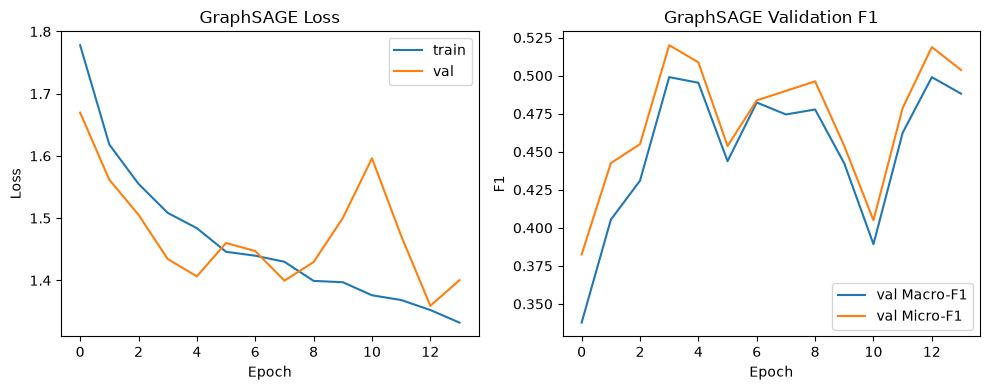

In [28]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gnn_history["train_loss"], label="train")
plt.plot(gnn_history["val_loss"], label="val")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GraphSAGE Loss"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(gnn_history["val_macro_f1"], label="val Macro-F1")
plt.plot(gnn_history["val_micro_f1"], label="val Micro-F1")
plt.xlabel("Epoch"); plt.ylabel("F1"); plt.title("GraphSAGE Validation F1"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["RESULTS_DIR"], "gnn_training_curves.png"), dpi=150)
plt.show()


## 7. CNN Baseline (mel-spectrogram, no graph, no text)

Per the spec's baseline list (**B2**): a plain CNN on log-mel spectrograms, with no structural
or textual information — this is the point of comparison for the GraphSAGE model.


In [29]:
def get_or_build_melspec(row, cfg):
    cache_path = os.path.join(cfg["CACHE_DIR"], "melspec", f"{row.track_id}_{cfg['FEATURE_VERSION']}.npy")
    if os.path.isfile(cache_path):
        return np.load(cache_path)
    try:
        y, _ = librosa.load(row.path, sr=cfg["SAMPLE_RATE"], mono=True)
        mel = librosa.feature.melspectrogram(y=y, sr=cfg["SAMPLE_RATE"], n_mels=cfg["N_MELS"])
        mel_db = librosa.power_to_db(mel, ref=np.max)
        # normalize per track
        mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-8)
        # pad/crop to fixed frame count
        T = cfg["MEL_FIXED_FRAMES"]
        if mel_db.shape[1] < T:
            mel_db = np.pad(mel_db, ((0, 0), (0, T - mel_db.shape[1])))
        else:
            mel_db = mel_db[:, :T]
        mel_db = mel_db.astype(np.float32)
        np.save(cache_path, mel_db)
        return mel_db
    except Exception:
        return None


class MelSpecDataset(TorchDataset):
    def __init__(self, ids_df, cfg):
        self.samples = []
        for row in tqdm(ids_df.itertuples(index=False), total=len(ids_df), desc="Building mel-specs"):
            mel = get_or_build_melspec(row, cfg)
            if mel is not None:
                self.samples.append((mel, row.label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        mel, label = self.samples[idx]
        return torch.tensor(mel).unsqueeze(0), torch.tensor(label, dtype=torch.long)


train_mel_ds = MelSpecDataset(split_df[split_df["split"] == "training"], CONFIG)
val_mel_ds   = MelSpecDataset(split_df[split_df["split"] == "validation"], CONFIG)
test_mel_ds  = MelSpecDataset(split_df[split_df["split"] == "test"], CONFIG)

train_mel_loader = TorchDataLoader(train_mel_ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)
val_mel_loader   = TorchDataLoader(val_mel_ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)
test_mel_loader  = TorchDataLoader(test_mel_ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=False)

print(f"Mel train/val/test: {len(train_mel_ds)}/{len(val_mel_ds)}/{len(test_mel_ds)}")


Building mel-specs: 100%|██████████| 800/800 [01:20<00:00,  9.88it/s]


Mel train/val/test: 6394/800/800


In [30]:
class CNNBaseline(nn.Module):
    def __init__(self, num_classes, n_mels, n_frames):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def run_epoch_cnn(model, loader, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, all_preds, all_labels = 0.0, [], []
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if is_train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            all_preds.append(out.argmax(dim=1).cpu().numpy())
            all_labels.append(y.cpu().numpy())

    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    micro_f1 = f1_score(all_labels, all_preds, average="micro")
    return total_loss / len(loader.dataset), acc, macro_f1, micro_f1


cnn_model = CNNBaseline(NUM_CLASSES, CONFIG["N_MELS"], CONFIG["MEL_FIXED_FRAMES"]).to(DEVICE)
cnn_model, cnn_history = train_model(
    cnn_model, train_mel_loader, val_mel_loader, run_epoch_cnn,
    epochs=CONFIG["EPOCHS"], lr=CONFIG["LR"], weight_decay=CONFIG["WEIGHT_DECAY"],
    patience=CONFIG["PATIENCE"], tag="CNN",
)

cnn_test_loss, cnn_test_acc, cnn_test_macro_f1, cnn_test_micro_f1 = run_epoch_cnn(cnn_model, test_mel_loader, None)
print(f"\n[CNN] TEST — acc={cnn_test_acc:.4f} | macroF1={cnn_test_macro_f1:.4f} | microF1={cnn_test_micro_f1:.4f}")


[CNN] Epoch 01 | train_loss 1.6927 | val_loss 1.6005 | val_acc 0.4037 | val_macroF1 0.3848
[CNN] Epoch 02 | train_loss 1.4515 | val_loss 1.7508 | val_acc 0.4088 | val_macroF1 0.3654
[CNN] Epoch 03 | train_loss 1.3661 | val_loss 1.5525 | val_acc 0.4512 | val_macroF1 0.4087
[CNN] Epoch 04 | train_loss 1.3238 | val_loss 1.4349 | val_acc 0.4875 | val_macroF1 0.4982
[CNN] Epoch 05 | train_loss 1.3097 | val_loss 1.5144 | val_acc 0.4813 | val_macroF1 0.4605
[CNN] Epoch 06 | train_loss 1.2690 | val_loss 1.3211 | val_acc 0.5787 | val_macroF1 0.5572
[CNN] Epoch 07 | train_loss 1.2375 | val_loss 1.3007 | val_acc 0.5750 | val_macroF1 0.5490
[CNN] Epoch 08 | train_loss 1.2224 | val_loss 1.4328 | val_acc 0.5400 | val_macroF1 0.5072
[CNN] Epoch 09 | train_loss 1.1846 | val_loss 1.2527 | val_acc 0.5675 | val_macroF1 0.5683
[CNN] Epoch 10 | train_loss 1.1750 | val_loss 1.7343 | val_acc 0.4575 | val_macroF1 0.4503
[CNN] Epoch 11 | train_loss 1.1306 | val_loss 1.3363 | val_acc 0.5613 | val_macroF1 0.5449

## 8. Comparison: GraphSAGE vs. CNN baseline

Per the rubric's "Baseline comparison" (≥2 baselines with fair experimental setup) and
Task 2's required deliverable "Comparison vs. CNN baseline on mel-spectrogram".


                    Model  Accuracy  Macro-F1  Micro-F1
    CNN (mel-spectrogram)    0.4700  0.465851    0.4700
GraphSAGE (segment graph)    0.3775  0.354710    0.3775


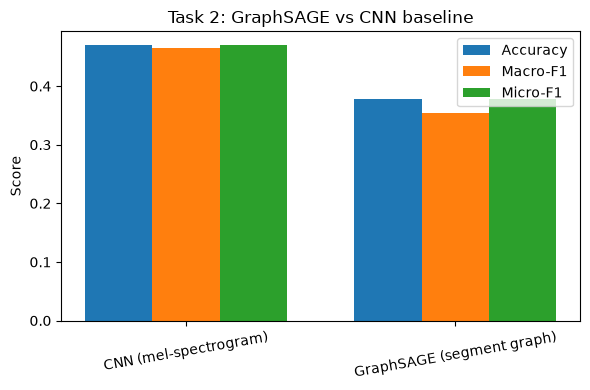

In [31]:
results_table = pd.DataFrame([
    {"Model": "CNN (mel-spectrogram)", "Accuracy": cnn_test_acc, "Macro-F1": cnn_test_macro_f1, "Micro-F1": cnn_test_micro_f1},
    {"Model": "GraphSAGE (segment graph)", "Accuracy": test_acc, "Macro-F1": test_macro_f1, "Micro-F1": test_micro_f1},
])
print(results_table.to_string(index=False))

results_table.to_csv(os.path.join(CONFIG["RESULTS_DIR"], "task2_results.csv"), index=False)

plt.figure(figsize=(6, 4))
x = np.arange(len(results_table))
width = 0.25
for i, metric in enumerate(["Accuracy", "Macro-F1", "Micro-F1"]):
    plt.bar(x + i * width, results_table[metric], width, label=metric)
plt.xticks(x + width, results_table["Model"], rotation=10)
plt.ylabel("Score"); plt.title("Task 2: GraphSAGE vs CNN baseline"); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["RESULTS_DIR"], "task2_comparison.png"), dpi=150)
plt.show()


## 9. Save artifacts for the report / GitHub submission

Saves: trained weights, results table, config, and a per-class classification report — matching
the `results/metrics.json` + `results/plots/` structure expected in the final submission.


In [32]:
torch.save(gnn_model.state_dict(), os.path.join(CONFIG["RESULTS_DIR"], "graphsage_task2.pt"))
torch.save(cnn_model.state_dict(), os.path.join(CONFIG["RESULTS_DIR"], "cnn_baseline_task2.pt"))

with open(os.path.join(CONFIG["RESULTS_DIR"], "config.json"), "w") as f:
    json.dump({k: v for k, v in CONFIG.items()}, f, indent=2)

metrics = {
    "cnn": {"accuracy": cnn_test_acc, "macro_f1": cnn_test_macro_f1, "micro_f1": cnn_test_micro_f1},
    "graphsage": {"accuracy": test_acc, "macro_f1": test_macro_f1, "micro_f1": test_micro_f1},
    "classes": list(le.classes_),
}
with open(os.path.join(CONFIG["RESULTS_DIR"], "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved model weights, config, and metrics to:", CONFIG["RESULTS_DIR"])


Saved model weights, config, and metrics to: ./results


In [33]:
torch.save(gnn_model.state_dict(), os.path.join(CONFIG["RESULTS_DIR"], "graphsage_task2.pt"))
torch.save(cnn_model.state_dict(), os.path.join(CONFIG["RESULTS_DIR"], "cnn_baseline_task2.pt"))

with open(os.path.join(CONFIG["RESULTS_DIR"], "config.json"), "w") as f:
    json.dump({k: v for k, v in CONFIG.items()}, f, indent=2)

metrics = {
    "cnn": {"accuracy": cnn_test_acc, "macro_f1": cnn_test_macro_f1, "micro_f1": cnn_test_micro_f1},
    "graphsage": {"accuracy": test_acc, "macro_f1": test_macro_f1, "micro_f1": test_micro_f1},
    "classes": list(le.classes_),
}
with open(os.path.join(CONFIG["RESULTS_DIR"], "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved model weights, config, and metrics to:", CONFIG["RESULTS_DIR"])

print("\n" + "=" * 50)
print("             TASK 2 TEST RESULTS COMPARISON")
print("=" * 50)
print(f"{'Model':<14} | {'Accuracy':<10} | {'Macro-F1':<10} | {'Micro-F1':<10}")
print("-" * 50)
print(f"{'CNN Baseline':<14} | {cnn_test_acc:.4f}     | {cnn_test_macro_f1:.4f}     | {cnn_test_micro_f1:.4f}")
print(f"{'GraphSAGE GNN':<14} | {test_acc:.4f}     | {test_macro_f1:.4f}     | {test_micro_f1:.4f}")
print("=" * 50)

Saved model weights, config, and metrics to: ./results

             TASK 2 TEST RESULTS COMPARISON
Model          | Accuracy   | Macro-F1   | Micro-F1  
--------------------------------------------------
CNN Baseline   | 0.4700     | 0.4659     | 0.4700
GraphSAGE GNN  | 0.3775     | 0.3547     | 0.3775


## Notes / things to check before you submit

- **If `tracks.csv` isn't in your Kaggle download**: grab `fma_metadata.zip` from the
  [official FMA repo](https://github.com/mdeff/fma) and point `METADATA_DIR` at it.
- **Quick smoke test**: set `CONFIG["MAX_TRACKS"] = 300` first to make sure the whole pipeline
  runs end-to-end in a few minutes before launching the full run on ~8,000 tracks.
- **Runtime expectation**: chroma/mel extraction over ~8,000 30-second clips on your CPU will
  likely be the slowest step (10-30+ min depending on disk speed) — it's cached to `.pt`/`.npy`
  so you only pay this cost once.
- **A few FMA-small mp3s are known to be corrupted** — these are silently skipped via the
  try/except in `get_or_build_graph` / `get_or_build_melspec`; check `failed_ids` if the count
  seems high.
- For the report's t-SNE visualization mentioned under Task 3, the GraphSAGE model already
  returns the pooled embedding `g` from `forward()` — you can reuse it directly when you get to
  Task 3.
